The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


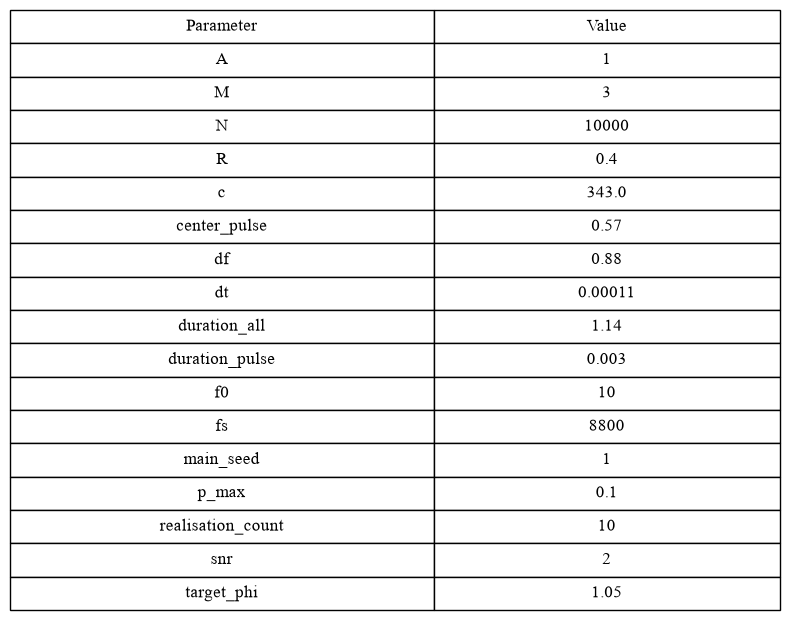

In [4]:
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt
import src.configs.config as cfg
import src.spectrum as spectrum
import src.signals as signals
import src.model as model
import src.configs.comon as comon
import os
import src.plotting as plotting


config_parametrs = cfg.init_rng()
path = "attachment/images/notebook"
os.makedirs(path,exist_ok=True)

plotting.create_config_table(config_parametrs)


$
p(t) = p_{max}\frac{\tau^2}{\tau^2 + (t-t_0)^2}
$

In [5]:
lorenth = signals.lorenth(config_parametrs)

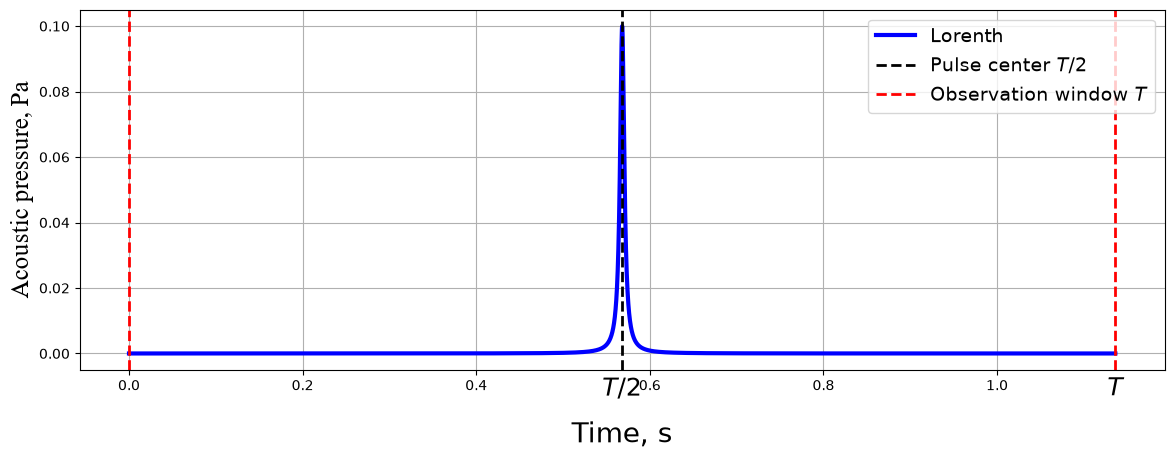

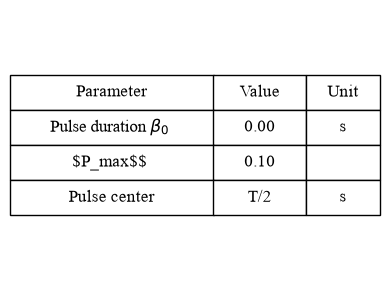

In [6]:
# Построение графика
title_main = "Lorenth pulse"
fig, ax = plt.subplots(1, 1, figsize = comon.FIG_SIZE)
fig.subplots_adjust(top=0.85, bottom=0.25)


ax.plot(
    cfg.TIME_VECTOR, lorenth,
    color="blue", linewidth=3, label="Lorenth"
)

# Названия осей и заголовок
ax.set_xlabel("Time, s", labelpad=20, fontsize=20)
ax.set_ylabel("Acoustic pressure, Pa", fontsize=18, fontfamily="Times New Roman")


# Центр импульса и отметки времени.
ax.axvline(
    config_parametrs["center_pulse"],
    color="black", linestyle="--", linewidth=2,
    label="Pulse center $T/2$"
)
ax.axvline(
    0,
    color="red", linestyle="--", linewidth=2,
)
ax.axvline(
    config_parametrs["duration_all"],
    color="red", linestyle="--", linewidth=2,
    label="Observation window $T$"
)
ax.text(
    config_parametrs["center_pulse"], -0.02, r"$T/2$",
    transform=ax.get_xaxis_transform(),
    ha="center", va="top", fontsize=18
)
ax.text(
    config_parametrs["duration_all"], -0.02, r"$T$",
    transform=ax.get_xaxis_transform(),
    ha="center", va="top", fontsize=18
)

ax.grid(True)
ax.legend(loc="upper right", fontsize=14)

# Параметры под графиком.
plt.savefig(fname = f"attachment/images/notebook/{title_main}", bbox_inches = 'tight', dpi = 300)
plt.show()

rows = [
    [r"Pulse duration $\beta_{\mathrm{0}}$ ", f"{comon.BETTA_PULSE:.2f}", "s"],
    [r"$P_max$$ ", f"{comon.LORENTZ_P_MAX:.2f}", " "],
    [r"Pulse center", f"T/2", "s"]]
plotting.create_and_save_table(rows, ["Parameter", "Value", "Unit"], f"attachment/images/notebook/table_{title_main}")